# MANUTENCAO EFICIENTE

## Fase 1 - Análise Exploratória (EDA)

In [175]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# Carregamento e Leitura da Base de Dados (Arquivo CSV)
df = pd.read_csv("https://raw.githubusercontent.com/NathaliaBerg/Manutencao_Eficiente_Final/main/data004/manutencao_preditiva.csv")

print("Base carregada com sucesso")
print(f"Dimensoes: {df.shape[0]} linhas e {df.shape[1]} colunas")

display(df.head())

Base carregada com sucesso
Dimensoes: 10000 linhas e 14 colunas


,udi,id_produto,tipo,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min,falha_maquina,falha_twf,falha_hdf,falha_pwf,falha_osf,falha_rnf
0,1,M14860,M,298.1,308.6,1551.0,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408.0,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498.0,49.4,5,0,0,0,0,0,0
3,4,L47183,L,NaN,NaN,NaN,NaN,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408.0,40.0,9,0,0,0,0,0,0


In [176]:
# Verificação de Versões das Bibliotecas
!pip freeze | grep -iE "pandas|numpy|scikit-learn|matplotlib|seaborn|imbalanced-learn"

geopandas==1.2.0
imbalanced-learn==0.14.2
matplotlib==3.10.0
matplotlib-inline==0.2.2
matplotlib-venn==1.1.2
numpy==2.1.3
pandas==2.2.3
pandas-datareader==0.11.1
pandas-gbq==0.30.0
pandas-stubs==2.2.3.250527
scikit-learn==1.6.1
seaborn==0.13.2
sklearn-pandas==2.2.0


### Justificativa: Registro mantido para auxiliar na documentação e reprodução do ambiente

In [177]:
# Verificação de Estrutura do dataset, tipos de dados e valores ausentes
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   udi                      10000 non-null  int64  
 1   id_produto               10000 non-null  object 
 2   tipo                     10000 non-null  object 
 3   temperatura_ar_k         9500 non-null   float64
 4   temperatura_processo_k   9500 non-null   float64
 5   velocidade_rotacao_rpm   9500 non-null   float64
 6   torque_nm                9500 non-null   float64
 7   desgaste_ferramenta_min  10000 non-null  int64  
 8   falha_maquina            10000 non-null  int64  
 9   falha_twf                10000 non-null  int64  
 10  falha_hdf                10000 non-null  int64  
 11  falha_pwf                10000 non-null  int64  
 12  falha_osf                10000 non-null  int64  
 13  falha_rnf                10000 non-null  int64  
dtypes: float64(4), int64(8)

In [178]:
# Análise estatística descritiva das variáveis numéricas
df.describe().T

,count,mean,std,min,25%,50%,75%,max
udi,10000.0,5000.500000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
temperatura_ar_k,9500.0,300.002158,2.001689,295.3,298.30,300.1,301.50,304.5
temperatura_processo_k,9500.0,310.000895,1.486432,305.7,308.80,310.1,311.10,313.8
velocidade_rotacao_rpm,9500.0,1539.245263,180.273589,1168.0,1423.00,1504.0,1613.00,2886.0
torque_nm,9500.0,39.974168,9.995453,3.8,33.10,40.1,46.70,76.6
desgaste_ferramenta_min,10000.0,107.951000,63.654147,0.0,53.00,108.0,162.00,253.0
falha_maquina,10000.0,0.033900,0.180981,0.0,0.00,0.0,0.00,1.0
falha_twf,10000.0,0.004600,0.067671,0.0,0.00,0.0,0.00,1.0
falha_hdf,10000.0,0.011500,0.106625,0.0,0.00,0.0,0.00,1.0
falha_pwf,10000.0,0.009500,0.097009,0.0,0.00,0.0,0.00,1.0


In [179]:
# Quantidade e Percentual de Valores Ausentes por coluna
valores_ausentes = pd.DataFrame({
    "valores_ausentes": df.isnull().sum(),
    "percentual (%)": df.isnull().mean().mul(100).round(2)

})

display(valores_ausentes[valores_ausentes["valores_ausentes"]>0])

,valores_ausentes,percentual (%)
temperatura_ar_k,500,5.0
temperatura_processo_k,500,5.0
velocidade_rotacao_rpm,500,5.0
torque_nm,500,5.0


In [180]:
# Quantidade de linhas duplicadas e identificadores UDI repetidos
print("Linhas duplicadas:", df.duplicated().sum())
print("Identificadores UDI repetidos:", df["udi"].duplicated().sum())

Linhas duplicadas: 0
Identificadores UDI repetidos: 0


In [181]:
# Mostra se os primeiros valores de udi são únicos

#VOLTAR AQUI PRA DIGITAR ESSE CODIGO NA UNHA
print(df["udi"].head(10).tolist())
print("Total de linhas:", len(df))
print("Valores únicos de udi:", df["udi"].nunique())

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
Total de linhas: 10000
Valores únicos de udi: 10000


In [182]:
# Checagem de duplicatas completas e UDI de forma limpa
total_duplicadas = df.duplicated().sum()
print("Linhas duplicadas no total:", total_duplicadas)
print("Total de IDs de UDI únicos:", df["udi"].nunique())

Linhas duplicadas no total: 0
Total de IDs de UDI únicos: 10000


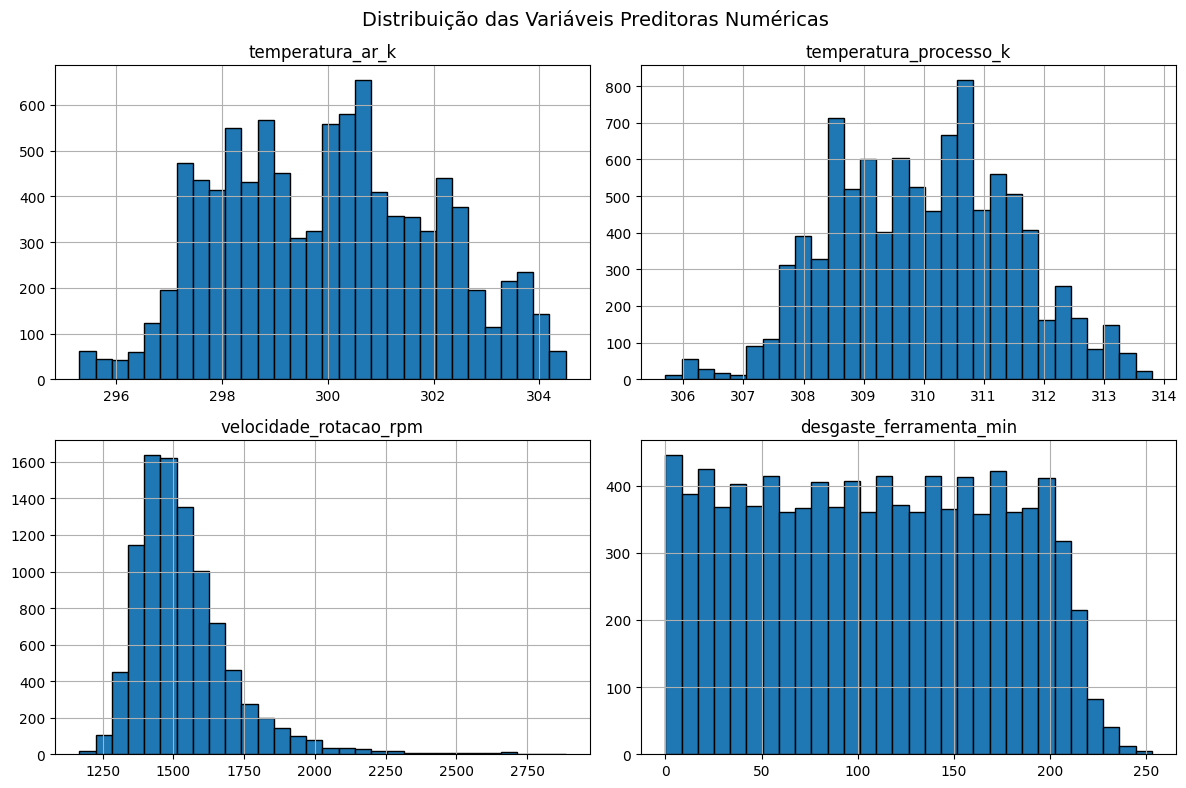

In [183]:
# Grafico 1: Histograma das variáveis preditoras numéricas
colunas_num = ['temperatura_ar_k', 'temperatura_processo_k', 'velocidade_rotacao_rpm', 'desgaste_ferramenta_min']
df[colunas_num].hist(bins=30, figsize=(12, 8), edgecolor='black')
plt.suptitle('Distribuição das Variáveis Preditoras Numéricas', fontsize=14)
plt.tight_layout()
plt.show()

/tmp/ipykernel_2648/734908099.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='falha_maquina', data=df, palette='Set2')


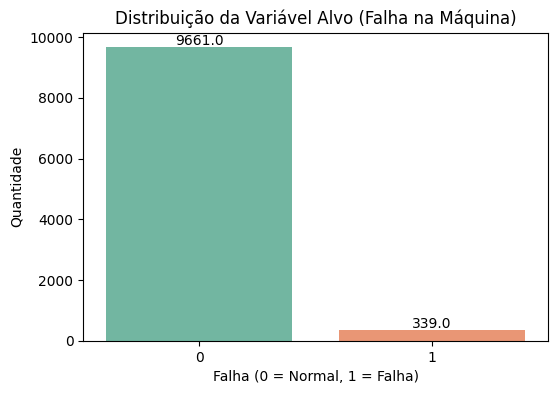

In [184]:
# Gráfico 2: Gráfico de barras da variável alvo (falha_maquina)
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='falha_maquina', data=df, palette='Set2')
plt.title('Distribuição da Variável Alvo (Falha na Máquina)')
plt.xlabel('Falha (0 = Normal, 1 = Falha)')
plt.ylabel('Quantidade')

#Adiciona os valores em cima de cada barra
for p in ax.patches:
  ax.annotate(f'{p.get_height()}', (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.show()

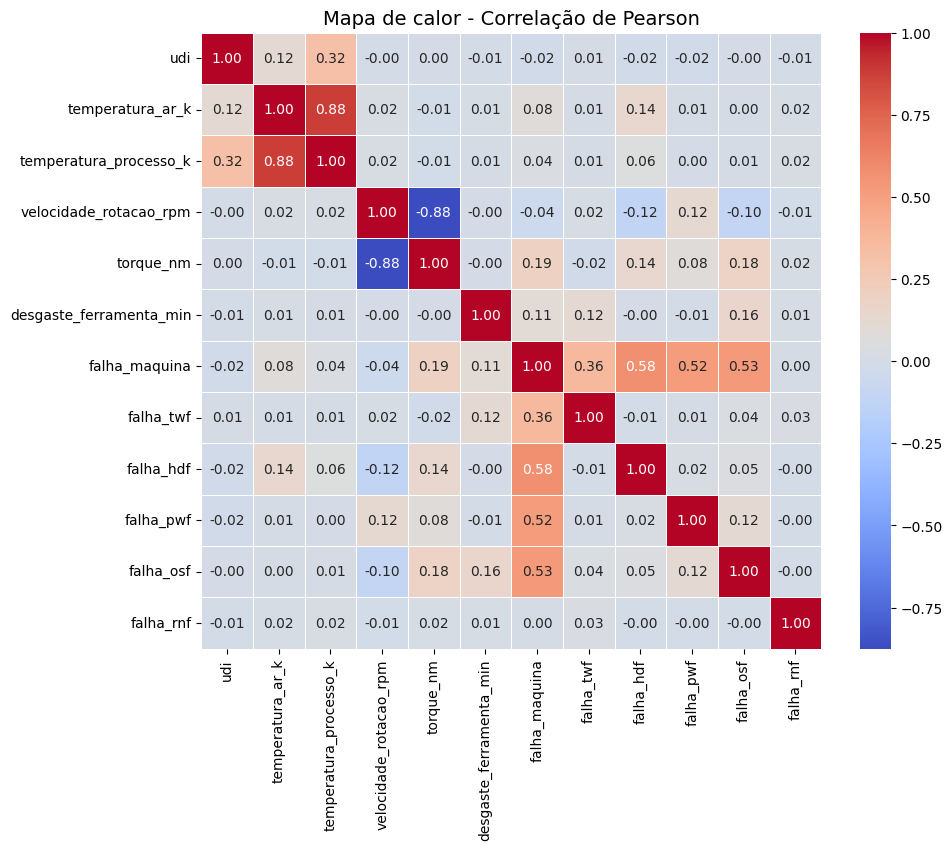

In [185]:
# Gráfico 3: Mapa de calor da correlação de Pearson
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Mapa de calor - Correlação de Pearson', fontsize=14)
plt.show()

### Análise da Fase 1 (EDA)
- **Dimensões e Tipos**: A base possui 10.000 linhas e 14 colunas com dados numéricos e categóricos.
- **Distribuição e Desbalanceamento**: O gráfico da variável alvo ('falha_maquina') comprova o forte desbalanceamento da base (aprox. 3,39% de falhas contra 96,61% de funcionamento normal), gerando uma acuracia ingênua de 96,6%, justificando o uso posterior de estratificação e técnicas de reamostragem como o SMOTE.
- **Correlações e Escalas**: O describe e os graficos mostram escalas muito variadas entre os sensores (ex: rotação na casa dos milhares e torque na casa das dezenas), justificando a necessidade de escalonamento futuro para algoritmos sensíveis à distância.

## Fase 2 - Limpeza e Tratamento de Dados (Data Prep)

In [186]:
# Fase 2: Tratamento de valores nulos nos sensores com a mediana e validação de duplicatas
colunas_sensores = ['temperatura_ar_k', 'temperatura_processo_k', 'velocidade_rotacao_rpm', 'torque_nm']

#2.1 Verificação inicial de nulos e linhas duplicadas
print("Total de linhas duplicadas:", df.duplicated().sum())
print("Nulos antes do tratamento:\n", df[colunas_sensores].isnull().sum())

#2.2 Imputação dos nulos pela mediana (conforme padrão tecnico robusto para outliers)
df[colunas_sensores] = df[colunas_sensores].fillna(df[colunas_sensores].median())

#2.3 Confirmação pós-imputação
print("\nNulos após o tratamento:\n", df[colunas_sensores].isnull().sum())

Total de linhas duplicadas: 0
Nulos antes do tratamento:
 temperatura_ar_k          500
temperatura_processo_k    500
velocidade_rotacao_rpm    500
torque_nm                 500
dtype: int64

Nulos após o tratamento:
 temperatura_ar_k          0
temperatura_processo_k    0
velocidade_rotacao_rpm    0
torque_nm                 0
dtype: int64


In [187]:
#2.4 Verificação final dos tipos de dados
print(df.dtypes)

udi                          int64
id_produto                  object
tipo                        object
temperatura_ar_k           float64
temperatura_processo_k     float64
velocidade_rotacao_rpm     float64
torque_nm                  float64
desgaste_ferramenta_min      int64
falha_maquina                int64
falha_twf                    int64
falha_hdf                    int64
falha_pwf                    int64
falha_osf                    int64
falha_rnf                    int64
dtype: object


### Análise da Fase 2 (Data Prep)
- **Justificativa tecnica**: Imputação dos valores ausentes (5% da base) utilizando a **mediana** de cada coluna de sensor. Essa abordagem é estatisticamente mais robusta que a média, pois protege o pipeline contra distorções causadas por possíveis outliers presentes nas medições industriais

## Fase 3 - Feature Engineering

In [188]:
import numpy as np

#3.1 Criação da diferença de temperatura (Delta T)
df['diferenca_temperatura_k'] = df['temperatura_processo_k'] - df['temperatura_ar_k']

#3.2 Criação da estimativa de potência mecânica em kW
df['potencia_kw'] = (df['torque_nm'] * df['velocidade_rotacao_rpm'] * 2 * np.pi) / 60000

#3.3 Verificação das novas colunas criadas
print("Primeiras linhas com as novas features:")
print(df[['diferenca_temperatura_k', 'potencia_kw']].head())

Primeiras linhas com as novas features:
   diferenca_temperatura_k  potencia_kw
0                     10.5     6.951591
1                     10.5     6.826723
2                     10.4     7.749388
3                     10.0     6.315690
4                     10.5     5.897817


### Análise da Fase 3 (Feature Engineering)
- **Justificativa Técnica**: criação de duas novas variáveis estratégicas **(Diferença de temperatura e Potência Mecânica)** a partir das variaveis de processo existentes para ajudar os modelos preditivos no futuro.

**Diferença de temperatura** do processo e do ar, para sinalizar estresse térmico e evitar falhas por superaquecimento.

**Potência Mecânica** combina o torque e a velocidade de rotação para detectar ineficiências energéticas e sobrecarga do motor.

## Fase 4 - Divisão e Balanceamento dos Dados

Os dados serão divididos em conjuntos de treino (80%) e teste (20%), utilizando estratificação para preservar a proporção das classes da variável-alvo falha_maquina. O parâmetro random_state=42 garante a reprodutibilidade da divisão.

O SMOTE será aplicado exclusivamente aos dados de treino para reduzir o desbalanceamento entre as classes. Os dados de teste permanecerão sem balanceamento artificial, permitindo avaliar os modelos em dados que preservam a distribuição original.

In [189]:

from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
import pandas as pd

# 4.1 Separação das variáveis preditoras e da variável-alvo
colunas_excluir = [
    'udi',
    'id_produto',
    'falha_maquina',
    'falha_twf',
    'falha_hdf',
    'falha_pwf',
    'falha_osf',
    'falha_rnf'
]

X = df.drop(columns=colunas_excluir, errors='ignore')
y = df['falha_maquina']

# 4.2 Conversão da variável categórica "tipo" em colunas numéricas
X = pd.get_dummies(X, columns=['tipo'], drop_first=True, dtype=int)

# 4.3 Separação em treino (80%) e teste (20%), com estratificação
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 4.4 Balanceamento somente dos dados de treino
smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train, y_train
)

# 4.5 Verificação dos resultados
print("Dimensões dos dados:")
print("Treino original:", X_train.shape)
print("Treino balanceado:", X_train_balanced.shape)
print("Teste:", X_test.shape)

print("\nClasses antes do SMOTE:")
print(y_train.value_counts())

print("\nClasses após o SMOTE:")
print(y_train_balanced.value_counts())

print("\nClasses no teste, sem balanceamento:")
print(y_test.value_counts())


Dimensões dos dados:
Treino original: (8000, 9)
Treino balanceado: (15458, 9)
Teste: (2000, 9)

Classes antes do SMOTE:
falha_maquina
0    7729
1     271
Name: count, dtype: int64

Classes após o SMOTE:
falha_maquina
0    7729
1    7729
Name: count, dtype: int64

Classes no teste, sem balanceamento:
falha_maquina
0    1932
1      68
Name: count, dtype: int64


**Exclusão das colunas:** evita usar identificadores e informações que revelam diretamente o tipo de falha.



**Estratificação:** mantém aproximadamente a mesma proporção de falhas no treino e no teste.



**SMOTE somente no treino:** impede que dados sintéticos contaminem a avaliação.



**Teste sem balanceamento:** mantém a distribuição real das classes para a avaliação final.

**Análise da Fase 4** — Separação e balanceamento

A divisão estratificada gerou 8.000 registros para treino e 2.000 para teste, preservando aproximadamente a proporção original das classes. No conjunto de treino, havia 7.729 registros sem falha e 271 com falha. Após a aplicação do SMOTE exclusivamente no treino, ambas as classes passaram a ter 7.729 registros.

O conjunto de teste permaneceu sem balanceamento artificial, com 1.932 registros sem falha e 68 com falha, preservando a distribuição observada nos dados. Essa separação permite treinar os modelos com classes equilibradas e avaliá-los em dados de teste que mantêm o desbalanceamento original.

## Fase 5 - Escalonamento

## Fase 5 — Padronização dos dados
O objetivo é colocar as variáveis numéricas em escalas comparáveis para o KNN, sem alterar os dados usados pela Árvore de Decisão.

O StandardScaler será utilizado para padronizar as variáveis preditoras do KNN, ajustando-as com base na média e no desvio-padrão dos dados de treino. Em seguida, a mesma transformação será aplicada aos dados de teste, evitando vazamento de informações.

A padronização será utilizada apenas no KNN, pois esse algoritmo calcula distâncias entre observações e é sensível às escalas das variáveis. A Árvore de Decisão não exige padronização, pois suas divisões são baseadas em limiares das variáveis, e não em distâncias.


In [190]:

from sklearn.preprocessing import StandardScaler

# 5.1 Criação do padronizador
scaler = StandardScaler()

# 5.2 Ajuste e transformação dos dados de treino balanceados
X_train_scaled = scaler.fit_transform(X_train_balanced)

# 5.3 Aplicação da mesma transformação aos dados de teste
X_test_scaled = scaler.transform(X_test)

# 5.4 Verificação das dimensões
print("Dimensões dos dados padronizados:")
print("Treino para KNN:", X_train_scaled.shape)
print("Teste para KNN:", X_test_scaled.shape)

print("\nMédia aproximada das variáveis no treino padronizado:")
print(X_train_scaled.mean(axis=0).round(2))

print("\nDesvio-padrão aproximado das variáveis no treino padronizado:")
print(X_train_scaled.std(axis=0).round(2))


Dimensões dos dados padronizados:
Treino para KNN: (15458, 9)
Teste para KNN: (2000, 9)

Média aproximada das variáveis no treino padronizado:
[ 0. -0.  0.  0.  0. -0.  0. -0.  0.]

Desvio-padrão aproximado das variáveis no treino padronizado:
[1. 1. 1. 1. 1. 1. 1. 1. 1.]


Por que usar fit_transform no treino e apenas transform no teste? Porque a média e o desvio-padrão devem ser calculados somente a partir do treino. Isso evita que o teste influencie a preparação dos dados.
A Árvore de Decisão continuará usando X_train_balanced e X_test, sem padronização.

**Análise da Fase 5** — Padronização

A padronização foi executada corretamente: as nove variáveis apresentaram médias próximas de zero e desvios-padrão iguais a um no conjunto de treino. O conjunto de teste recebeu a mesma transformação, sem recalcular os parâmetros.

Os dados padronizados serão utilizados pelo KNN, enquanto a Árvore de Decisão utilizará os dados sem padronização, pois esse modelo não depende de cálculos de distância.

## Fase 6 - Ajuste de parâmetros e Combate ao Overfitting

teste de diferentes configurações do KNN e da Árvore de Decisão e comparar o desempenho no treino e no teste para identificar sinais de overfitting.

Nesta fase, serão treinados modelos KNN e Árvore de Decisão com diferentes hiperparâmetros. O KNN será testado com diferentes valores ímpares de n_neighbors, enquanto a Árvore de Decisão será avaliada com diferentes valores de max_depth.

O desempenho será comparado pelas acurácias nos conjuntos de treino e teste. Diferenças elevadas entre essas métricas podem indicar overfitting, situação em que o modelo se ajusta excessivamente aos dados de treino e apresenta menor capacidade de generalização.

In [191]:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
import pandas as pd

resultados = []

# 6.1 Avaliação do KNN com valores ímpares de n_neighbors
for k in [3, 5, 7, 9, 11]:
    modelo_knn = KNeighborsClassifier(n_neighbors=k)
    modelo_knn.fit(X_train_scaled, y_train_balanced)

    pred_treino = modelo_knn.predict(X_train_scaled)
    pred_teste = modelo_knn.predict(X_test_scaled)

    resultados.append({
        'Modelo': 'KNN',
        'Hiperparâmetro': f'n_neighbors={k}',
        'Acurácia treino': accuracy_score(y_train_balanced, pred_treino),
        'Acurácia teste': accuracy_score(y_test, pred_teste)
    })

# 6.2 Avaliação da Árvore de Decisão com diferentes profundidades
for profundidade in [3, 5, 10, None]:
    modelo_arvore = DecisionTreeClassifier(
        max_depth=profundidade,
        random_state=42
    )
    modelo_arvore.fit(X_train_balanced, y_train_balanced)

    pred_treino = modelo_arvore.predict(X_train_balanced)
    pred_teste = modelo_arvore.predict(X_test)

    resultados.append({
        'Modelo': 'Árvore de Decisão',
        'Hiperparâmetro': f'max_depth={profundidade}',
        'Acurácia treino': accuracy_score(y_train_balanced, pred_treino),
        'Acurácia teste': accuracy_score(y_test, pred_teste)
    })

# 6.3 Comparação dos resultados
df_resultados = pd.DataFrame(resultados)
print(df_resultados.round(4).to_string(index=False))


           Modelo Hiperparâmetro  Acurácia treino  Acurácia teste
              KNN  n_neighbors=3           0.9769          0.9150
              KNN  n_neighbors=5           0.9689          0.9070
              KNN  n_neighbors=7           0.9627          0.9050
              KNN  n_neighbors=9           0.9565          0.8985
              KNN n_neighbors=11           0.9532          0.8980
Árvore de Decisão    max_depth=3           0.8790          0.8685
Árvore de Decisão    max_depth=5           0.9320          0.9210
Árvore de Decisão   max_depth=10           0.9731          0.9375
Árvore de Decisão max_depth=None           0.9977          0.9460


**Análise da Fase 6** — Ajuste de hiperparâmetros

O KNN apresentou sua melhor acurácia de teste com n_neighbors=3 (91,50%). Conforme o número de vizinhos aumentou, a acurácia de teste diminuiu gradualmente.

A Árvore de Decisão apresentou sua maior acurácia de teste sem limite de profundidade (max_depth=None), atingindo 94,60%, com acurácia de treino de 99,77%. Essa diferença de 5,17 pontos percentuais indica possível overfitting. Com max_depth=10, o modelo obteve 93,75% no teste e 97,31% no treino, apresentando uma diferença menor.

Entre as configurações avaliadas, a Árvore de Decisão sem limite de profundidade obteve a maior acurácia de teste. A escolha final, entretanto, também deverá considerar a diferença entre treino e teste e a capacidade de generalização do modelo.

Sobre a avaliação dos dois conjuntos: A acurácia de treino mostra como o modelo se ajusta aos dados usados no aprendizado; a acurácia de teste indica seu desempenho em dados não usados no treinamento. Uma diferença grande entre elas pode sinalizar overfitting.

## Fase 7 - Avaliação da Acurácia e Veredito Final

Nesta fase, serão comparados os modelos selecionados a partir dos testes de hiperparâmetros. A avaliação utilizará a acurácia no conjunto de teste, que não participou do treinamento, e a diferença entre as acurácias de treino e teste, para analisar a capacidade de generalização.

O KNN será avaliado com n_neighbors=3. A Árvore de Decisão será avaliada com max_depth=10, configuração que apresentou acurácia de teste próxima à máxima obtida, com menor diferença entre treino e teste do que a árvore sem limite de profundidade.

In [192]:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
import pandas as pd

# 7.1 Treinamento dos modelos selecionados
knn_final = KNeighborsClassifier(n_neighbors=3)
knn_final.fit(X_train_scaled, y_train_balanced)

arvore_final = DecisionTreeClassifier(
    max_depth=10,
    random_state=42
)
arvore_final.fit(X_train_balanced, y_train_balanced)

# 7.2 Previsões nos conjuntos de treino e teste
knn_pred_treino = knn_final.predict(X_train_scaled)
knn_pred_teste = knn_final.predict(X_test_scaled)

arvore_pred_treino = arvore_final.predict(X_train_balanced)
arvore_pred_teste = arvore_final.predict(X_test)

# 7.3 Comparação final
avaliacao_final = pd.DataFrame([
    {
        'Modelo': 'KNN (n_neighbors=3)',
        'Acurácia treino': accuracy_score(y_train_balanced, knn_pred_treino),
        'Acurácia teste': accuracy_score(y_test, knn_pred_teste)
    },
    {
        'Modelo': 'Árvore de Decisão (max_depth=10)',
        'Acurácia treino': accuracy_score(y_train_balanced, arvore_pred_treino),
        'Acurácia teste': accuracy_score(y_test, arvore_pred_teste)
    }
])

avaliacao_final['Diferença treino-teste'] = (
    avaliacao_final['Acurácia treino'] -
    avaliacao_final['Acurácia teste']
)

print("Comparação final dos modelos:")
print(avaliacao_final.round(4).to_string(index=False))


Comparação final dos modelos:
                          Modelo  Acurácia treino  Acurácia teste  Diferença treino-teste
             KNN (n_neighbors=3)           0.9769          0.9150                  0.0619
Árvore de Decisão (max_depth=10)           0.9731          0.9375                  0.0356


Por que max_depth=10? Na Fase 6, essa configuração teve 93,75% de acurácia no teste, contra 94,60% da árvore sem limite de profundidade, mas apresentou uma diferença menor entre treino e teste. É uma escolha de compromisso entre desempenho e generalização.

**Conclusão da Fase 7 — Avaliação final**
A Árvore de Decisão com max_depth=10 foi selecionada como modelo final. Ela obteve acurácia de 93,75% no conjunto de teste, superior aos 91,50% do KNN com n_neighbors=3.

A diferença entre as acurácias de treino e teste foi de 3,56 pontos percentuais para a Árvore de Decisão, contra 6,19 pontos percentuais para o KNN. Esses resultados indicam melhor desempenho e menor diferença entre treino e teste para a Árvore de Decisão selecionada.

Conclui-se que a Árvore de Decisão com profundidade máxima de 10 apresentou o melhor equilíbrio entre acurácia e capacidade de generalização entre as configurações finais avaliadas. Em uma aplicação real de manutenção preditiva, também seria importante analisar métricas como precisão, recall e matriz de confusão, pois falhas não identificadas podem ter consequências operacionais relevantes.